<a href="https://colab.research.google.com/github/shrinidhisj1/4IK25CS192_DAV_LAB/blob/main/4IK25CS192_EXP_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment 10 K-Means, Clustering Applying K-Means on a dataset,elbow method to find optimal K visualizing clusters.

In [1]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

Load dataset and prepare features

In [2]:
df = pd.read_csv("/content/House_Price_dataset.csv")

df=df[df['purpose']=='For Sale'].copy()
df['Area']=df['Area Size']
df.loc[df['Area Type']=='Kanal','Area']=df['Area Size']*20
df=df[(df['Area']>0) & (df['price']>0)]
df=df[(df['Area']<df['Area'].quantile(0.99)) & (df['price'] < df['price'].quantile(0.99))]
df=df.sample(n=2000,random_state=42).copy()

X=df[['Area','price']]
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

Elbow Method to find optimal K

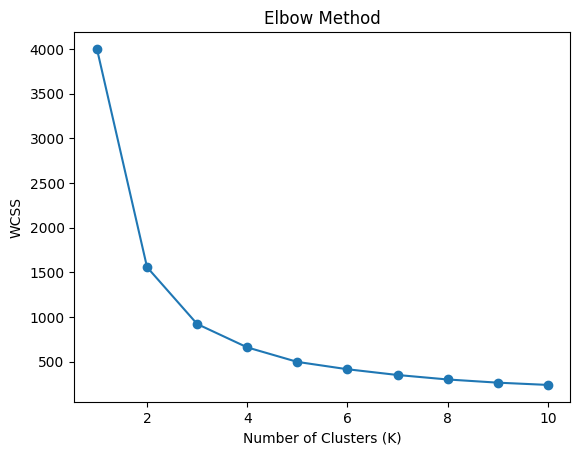

In [3]:
wcss=[]
for k in range(1,11):
  km=KMeans(n_clusters=k,random_state=42,n_init=10)
  km.fit(X_scaled)
  wcss.append(km.inertia_)
plt.plot(range(1,11),wcss,marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")

plt.title("Elbow Method")
plt.show()

Fill find model with choosen K

In [4]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

print(df['Cluster'].value_counts().sort_index())
print(df.groupby('Cluster')[['Area','price']].mean())

Cluster
0     353
1    1575
2      72
Name: count, dtype: int64
              Area         price
Cluster                         
0        18.598017  4.757139e+07
1         6.120254  1.276346e+07
2        30.272222  1.279167e+08


Visualize clusters

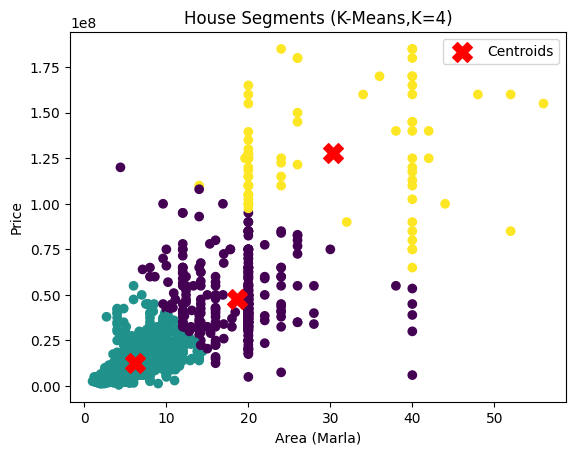

In [5]:
plt.scatter(df['Area'],df['price'],c=df['Cluster'],cmap='viridis')
centers=scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centers[:,0],centers[:,1],c='red',marker='X',s=200,label='Centroids')
plt.xlabel("Area (Marla)")
plt.ylabel("Price")
plt.title("House Segments (K-Means,K=4)")
plt.legend()
plt.show()